
Copyright (C) 2023 - 2026 Synopsys, Inc. and ANSYS, Inc. All rights reserved.
SPDX-License-Identifier: MIT


Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

In [1]:
from pathlib import Path
import sys
import tempfile

In [2]:
from ansys.aedt.core import generate_unique_project_name
from ansys.aedt.core.visualization.advanced.farfield_visualization import FfdSolutionData
from ansys.aedt.core.visualization.plot.pyvista import ModelPlotter
import pyvista as pv

In [3]:
from ansys.aedt.toolkits.antenna.backend.api import ToolkitBackend
from ansys.aedt.toolkits.antenna.backend.models import properties

##  Set AEDT version

Set AEDT version.

In [4]:
aedt_version = "2026.1"

## Set non-graphical mode

Set non-graphical mode.

In [5]:
non_graphical = False

## Set number of cores

In [6]:
num_cores = 4

## Create temporary directory

In [7]:
temp_dir = tempfile.TemporaryDirectory(suffix="_ansys")
project_name = generate_unique_project_name(root_name=temp_dir.name, project_name="antenna_toolkit")

## Set default properties

In [8]:
properties.aedt_version = aedt_version
properties.non_graphical = non_graphical
properties.active_project = project_name

## Initialize toolkit

Initialize the toolkit.

In [9]:
toolkit_api = ToolkitBackend()

## Get available_antennas

In [10]:
print(toolkit_api.available_antennas)

['BowTieNormal', 'BowTieRounded', 'BowTieSlot', 'Archimedean', 'Log', 'Sinuous', 'GPSPatchCeramic', 'PlanarDipole', 'WireDipole', 'AxialMode', 'AxialModeTaper', 'NormalMode', 'QuadrifilarOpen', 'QuadrifilarShort', 'Conical', 'Corrugated', 'Elliptical', 'EPlane', 'HPlane', 'Pyramidal', 'PyramidalRidged', 'QuadRidged', 'LogPeriodicArray', 'LogPeriodicToothed', 'LogPeriodicTrapezoidal', 'Bicone', 'Discone', 'BladeAntenna', 'CircularDiscMonopole', 'EllipticalBaseStripMonopole', 'VerticalTrapezoidalMonopole', 'WireMonopole', 'EllipticalEdge', 'EllipticalInset', 'EllipticalProbe', 'MbyNPatchArray', 'RectangularPatchEdge', 'RectangularPatchInset', 'RectangularPatchProbe', 'SeqRotated2Patch', 'PlanarInvertedF', 'ShortingPin', 'ShortingPlate', 'PlanarArchimedean', 'PlanarArchimedeanCavity', 'PlanarLog', 'PlanarLogCavity', 'PlanarSinuous', 'PlanarSinuousCavity', 'SlotCavityBackedArray', 'SlotGap', 'SlotMicrostrip', 'SlotTBar', 'Vivaldi', 'VivaldiStepped', 'CircularWaveguide', 'RectangularWavegui

## Get default properties

In [11]:
backend_properties = toolkit_api.get_properties()
frequency = backend_properties["antenna"]["synthesis"]["frequency"]
frequency_units = backend_properties["antenna"]["synthesis"]["frequency_unit"]
length_unit = backend_properties["antenna"]["synthesis"]["length_unit"]

## Modify default length units

In [12]:
properties.antenna.synthesis.length_unit = "cm"
properties.antenna.synthesis.substrate_height = 0.1

## Create antenna object only for synthesis

Create antenna object.

In [13]:
antenna_parameters_1 = toolkit_api.get_antenna("RectangularPatchProbe", synth_only=True)

INFO - AEDT is released.


In [14]:
print(
    "Patch X length: {}{} at {}{}".format(
        str(antenna_parameters_1["patch_x"]),
        length_unit,
        frequency,
        frequency_units,
    )
)

Patch X length: 0.912871mm at 10.0GHz


## Change synthesis frequency

Modify resonance frequency and modify parameters with the ``set_properties()`` method.

In [15]:
new_frequency1 = 12.0
new_properties = {"frequency": new_frequency1}
toolkit_api.set_properties(new_properties)

INFO - Updating internal properties.


DEBUG - Updating 'frequency' with value 12.0


DEBUG - Properties were updated successfully.


(True, 'Properties were updated successfully.')

In [16]:
antenna_parameters_2 = toolkit_api.get_antenna("RectangularPatchProbe", synth_only=True)

INFO - AEDT is released.


In [17]:
print(
    "Patch X length: {}{} at {}{}".format(
        str(antenna_parameters_2["patch_x"]),
        length_unit,
        new_frequency1,
        frequency_units,
    )
)

Patch X length: 0.760726mm at 12.0GHz


## Change synthesis frequency

Modify resonance frequency with properties directly.

In [18]:
new_frequency2 = 15.0
properties.antenna.synthesis.frequency = new_frequency2

In [19]:
antenna_parameters_3 = toolkit_api.get_antenna("RectangularPatchProbe", synth_only=True)

INFO - AEDT is released.


In [20]:
print(
    "Patch X length: {}{} at {}{}".format(
        str(antenna_parameters_3["patch_x"]),
        length_unit,
        new_frequency2,
        frequency_units,
    )
)

Patch X length: 0.608581mm at 15.0GHz


## Initialize AEDT

Launch a new AEDT session in a thread.

In [21]:
thread_msg = toolkit_api.launch_thread(toolkit_api.launch_aedt)

DEBUG - Starting thread: Toolkit_Thread


DEBUG - Toolkit is not connected to AEDT.


DEBUG - Launching AEDT


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing new Desktop session.


## Wait for the toolkit thread to be idle

Wait for the toolkit thread to be idle and ready to accept a new task.

In [22]:
idle = toolkit_api.wait_to_be_idle()
if not idle:
    print("AEDT not initialized.")
    sys.exit()

PyAEDT INFO: New AEDT session is starting on gRPC port 62514.


PyAEDT INFO: Starting new AEDT gRPC session on port 62514.


PyAEDT INFO: Launching AEDT server with gRPC transport mode: TransportMode.WNUA


DEBUG - Toolkit is busy and processing a task.


DEBUG - Toolkit is busy and processing a task.


DEBUG - Toolkit is busy and processing a task.


... (15 outputs left out)

INFO - AEDT is released.


DEBUG - AEDT released and properties loaded


DEBUG - Toolkit is busy and processing a task.


DEBUG - Toolkit is idle and ready to accept a new task.


## Connect to HFSS design

Create an HFSS design.

In [23]:
toolkit_api.connect_design("HFSS")

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (18 outputs left out)

DEBUG - Updating 'design_list' with value {'antenna_toolkit': ['HFSS_OO6YI5']}


DEBUG - Properties were updated successfully.


INFO - Toolkit is connected to AEDT design.


True

## Create setup when antenna is created

Set ``create_setup`` property.

In [24]:
properties.antenna.setup.create_setup = True
properties.antenna.synthesis.outer_boundary = "Radiation"

## Create antenna in HFSS

Create antenna and set up in HFSS.

In [25]:
antenna_parameter = toolkit_api.get_antenna("RectangularPatchProbe")

PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec


PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec


PyAEDT INFO: Open Region correctly created.


PyAEDT INFO: Project antenna_toolkit Saved correctly


PyAEDT INFO: Parsing design objects. This operation can take time


PyAEDT INFO: Refreshing bodies from Object Info


... (5 outputs left out)

PyAEDT INFO: Boundary AutoIdentify port_Patch_IPE37Y_1 has been created.


PyAEDT INFO: Project antenna_toolkit Saved correctly


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


## Plot antenna model

In [26]:
toolkit_api.connect_design("HFSS")
# Save the plot to display it
plot_obj = toolkit_api.aedtapp.plot(show=False, output_file=str(Path(temp_dir.name) / "antenna_model.png"))
toolkit_api.release_aedt(False, False)

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (20 outputs left out)

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


True

## Try to create antenna

The AEDT Antenna Toolkit API does not allow the creation of more than one antenna. However, you can use the antenna
model's API to create more than one antenna.

In [27]:
new_antenna = toolkit_api.get_antenna("BowTie")

DEBUG - Antenna is already created.


In [28]:
print(new_antenna)

False


## Set properties

Move antenna X position

In [29]:
toolkit_api.update_hfss_parameters("pos_x", "20")

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (11 outputs left out)

INFO - Toolkit is connected to AEDT design.


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


True

## Set properties

Move antenna X position to origin

In [30]:
toolkit_api.update_hfss_parameters("pos_x", "0")

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (11 outputs left out)

INFO - Toolkit is connected to AEDT design.


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


True

## Modify number of cores

In [31]:
properties.antenna.setup.num_cores = num_cores

## Analyze design in batch mode

In [32]:
toolkit_api.analyze()

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (17 outputs left out)

PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


True

## Get scattering results

In [33]:
scattering_data = toolkit_api.scattering_results()

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (20 outputs left out)

PyAEDT INFO: Solution Correctly loaded. Elapsed time: 0m 0sec


PyAEDT INFO: Solution Correctly parsed. Elapsed time: 0m 0sec


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


## Get farfield results

In [34]:
frequency_str = [str(properties.antenna.synthesis.frequency) + properties.antenna.synthesis.frequency_unit]
farfield_metadata, farfield_frequency = toolkit_api.export_farfield(
    frequencies=frequency_str, sphere="3D", encode=False
)

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (23 outputs left out)

PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec


PyAEDT INFO: Exporting embedded element patterns.... Done: 1.2804250717163086 seconds


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


## Get antenna model

In [35]:
files = toolkit_api.export_aedt_model(encode=False)

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (18 outputs left out)

PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec


PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec


PyAEDT INFO: Desktop has been released.


INFO - AEDT is released.


## Release AEDT

Release AEDT.

In [36]:
toolkit_api.release_aedt(True, True)

DEBUG - Toolkit is not connected to AEDT.


DEBUG - Connecting AEDT.


PyAEDT INFO: Python version 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)].


PyAEDT INFO: PyAEDT version 1.9.0.


PyAEDT INFO: Initializing Desktop session.


PyAEDT INFO: AEDT version 2026.1.


... (4 outputs left out)

DEBUG - Toolkit is connected to AEDT.


PyAEDT INFO: Desktop has been released and closed.


INFO - AEDT is released.


True

## Plot results

Plot exported 3D model

In [37]:
model_plotter = ModelPlotter()
for file in files:
    model_plotter.add_object(file[0], file[1], file[2])

In [38]:
# Plot the model
model_plotter.plot(show=True)

C:\actions-runner\_work\pyaedt-toolkits-antenna\pyaedt-toolkits-antenna\.venv\Lib\site-packages\ansys\aedt\core\visualization\plot\pyvista.py:1366: PyVistaDeprecationWarning: ``Plotter.button_widgets`` is deprecated; use ``Plotter.widgets.button_widgets`` instead.
  while len(self.plot.button_widgets) > 1:


EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

True

## Load far field

In [39]:
farfield_data = FfdSolutionData(farfield_metadata)

## Plot far field 3D

In [40]:
# Render 3D far field - in Jupyter, this will show as interactive 3D
pyvista_plotter = pv.Plotter(notebook=True, off_screen=non_graphical)
farfield_data.plot_3d(
    quantity="RealizedGain",
    show=False,
    pyvista_object=pyvista_plotter,
)
pyvista_plotter.show(jupyter_backend="html")

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

## Plot far field cut

Class: ansys.aedt.core.visualization.plot.matplotlib.ReportPlotter

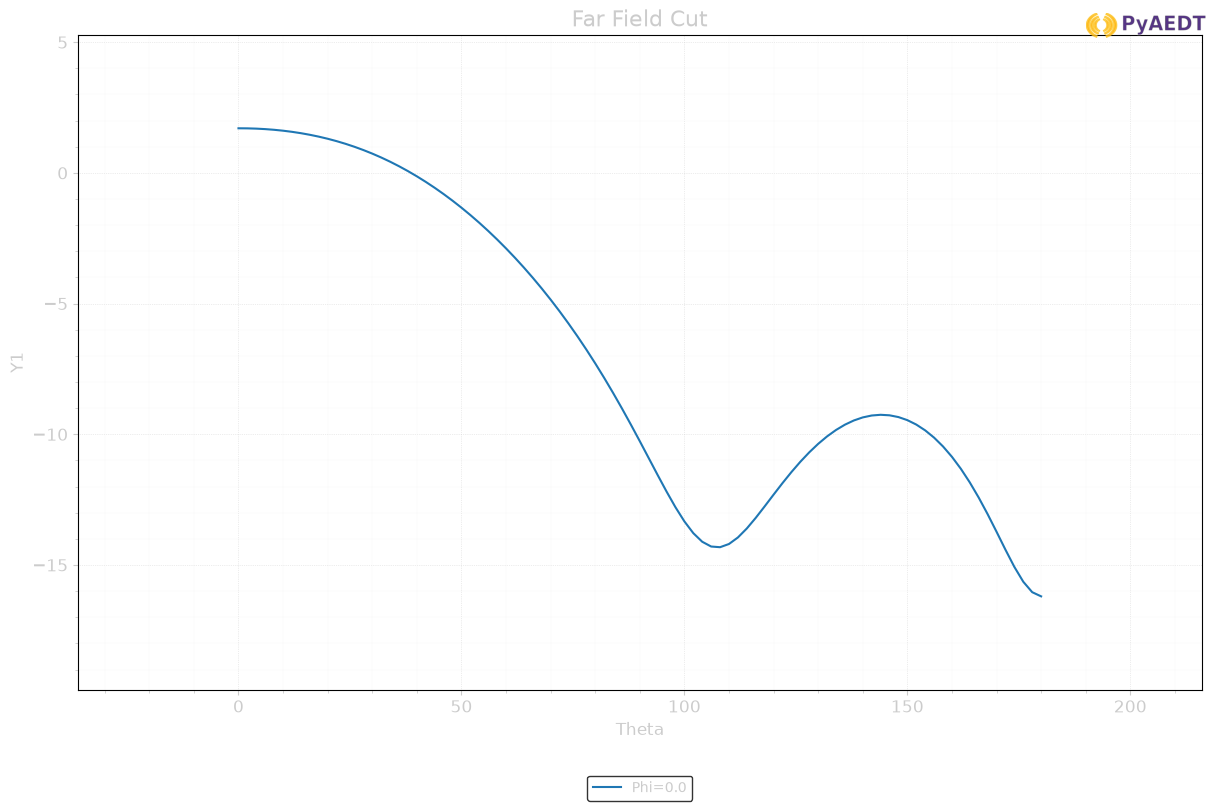

In [41]:
# Render far field cut plot
farfield_data.plot_cut(primary_sweep="theta", show=True)

## Clean temporary directory

In [42]:
temp_dir.cleanup()